In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("/content/bank-additional-full (3) (1).csv",sep = ";")

In [ ]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56.0,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261.0,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57.0,services,married,high.school,unknown,no,no,telephone,may,mon,149.0,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37.0,services,married,high.school,no,yes,no,telephone,may,mon,226.0,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40.0,admin.,married,basic.6y,no,no,no,telephone,may,mon,151.0,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56.0,services,married,high.school,no,no,yes,telephone,may,mon,307.0,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


age: Client's age (numeric).

job: Client's job type (categorical).

marital: Client's marital status (categorical).

education: Client's level of education (categorical).

default: Whether the client has credit in default (categorical: "yes"/"no").

housing: Whether the client has a housing loan (categorical: "yes"/"no").

loan: Whether the client has a personal loan (categorical: "yes"/"no").

contact: Type of communication contact (categorical: "cellular", "telephone", etc.).

month: Last contact month of the year (categorical).
day_of_week: Last contact day of the week (categorical).

duration: Last contact duration in seconds (numeric).

campaign: Number of contacts performed during this campaign (numeric).

pdays: Days since the client was last contacted from a previous campaign (numeric, -1 if not previously contacted).

previous: Number of contacts performed before this campaign (numeric).

poutcome: Outcome of the previous marketing campaign (categorical: "success", "failure", etc.).

emp.var.rate: Employment variation rate - quarterly indicator (numeric).

cons.price.idx: Consumer price index - monthly indicator (numeric).

cons.conf.idx: Consumer confidence index - monthly indicator (numeric).

euribor3m: Euribor 3-month rate - daily indicator (numeric).

nr.employed: Number of employees - quarterly indicator (numeric).

y (Target): Whether the client subscribed to a term deposit (binary: "yes" for success, "no" for failure).

In logistic regression, y is the dependent variable, with binary outcomes to predict (e.g., "yes" = 1, "no" = 0).

In [ ]:
#how many people have taken this term deposit and how many are not
df["y"].value_counts()

,count
y,
no,36556
yes,4640


In [ ]:
df["job"].value_counts()

,count
job,
admin.,10422
blue-collar,9254
technician,6743
services,3969
management,2924
retired,1726
entrepreneur,1456
self-employed,1421
housemaid,1060


In [ ]:
df["job"].value_counts(normalize = True)*100

,proportion
job,
admin.,25.299801
blue-collar,22.464437
technician,16.368889
services,9.634898
management,7.098121
retired,4.189931
entrepreneur,3.534495
self-employed,3.449531
housemaid,2.573190


In [ ]:
df["job"].unique()

array(['housemaid', 'services', 'admin.', 'blue-collar', 'technician',
       'retired', 'management', 'unemployed', 'self-employed', 'unknown',
       'entrepreneur', 'student', nan], dtype=object)

In [ ]:
df["job"].nunique()

12

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41199 entries, 0 to 41198
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41195 non-null  float64
 1   job             41194 non-null  object 
 2   marital         41194 non-null  object 
 3   education       41194 non-null  object 
 4   default         41195 non-null  object 
 5   housing         41196 non-null  object 
 6   loan            41195 non-null  object 
 7   contact         41195 non-null  object 
 8   month           41196 non-null  object 
 9   day_of_week     41196 non-null  object 
 10  duration        41196 non-null  float64
 11  campaign        41196 non-null  float64
 12  pdays           41196 non-null  float64
 13  previous        41196 non-null  float64
 14  poutcome        41194 non-null  object 
 15  emp.var.rate    41196 non-null  float64
 16  cons.price.idx  41195 non-null  float64
 17  cons.conf.idx   41196 non-null 

In [ ]:
df.isnull().sum()

,0
age,4
job,5
marital,5
education,5
default,4
housing,3
loan,4
contact,4
month,3
day_of_week,3


In [ ]:
df.isnull().sum().sum()

np.int64(76)

In [ ]:
df.shape

(41199, 21)

In [ ]:
#percentage of null values in the data

(76/41199)*100

0.18447049685671982

In [ ]:
#drop or replace
#as the percentage is less we need to drop them

df.dropna(inplace = True)

In [ ]:
df.isnull().sum().sum()

np.int64(0)

In [ ]:
df.shape

(41190, 21)

In [ ]:
#duplicate values

df.duplicated().sum()

np.int64(13)

In [ ]:
df.drop_duplicates(inplace = True)

In [ ]:
df

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56.0,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261.0,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57.0,services,married,high.school,unknown,no,no,telephone,may,mon,149.0,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37.0,services,married,high.school,no,yes,no,telephone,may,mon,226.0,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40.0,admin.,married,basic.6y,no,no,no,telephone,may,mon,151.0,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56.0,services,married,high.school,no,no,yes,telephone,may,mon,307.0,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41184,46.0,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,383.0,1.0,999.0,0.0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56.0,retired,married,university.degree,no,yes,no,cellular,nov,fri,189.0,2.0,999.0,0.0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44.0,technician,married,professional.course,no,no,no,cellular,nov,fri,442.0,1.0,999.0,0.0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41187,74.0,retired,married,professional.course,no,yes,no,cellular,nov,fri,239.0,3.0,999.0,1.0,failure,-1.1,94.767,-50.8,1.028,4963.6,no


In [ ]:
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41177.000000,41177.000000,41177.000000,41177.000000,41177.000000,41177.000000,41177.000000,41177.000000,41177.000000,41177.000000
mean,40.025111,258.315346,2.567890,962.465697,0.173033,0.081893,93.575749,-40.503113,3.621230,5167.029929
std,10.423948,259.302190,2.770286,186.934918,0.494975,1.570874,0.578862,4.628082,1.734463,72.257442
min,17.000000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.000000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.000000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.000000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.000000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [ ]:
df = df.rename(columns={"job": "jobs"})

In [ ]:
df

,age,jobs,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56.0,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261.0,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57.0,services,married,high.school,unknown,no,no,telephone,may,mon,149.0,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37.0,services,married,high.school,no,yes,no,telephone,may,mon,226.0,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40.0,admin.,married,basic.6y,no,no,no,telephone,may,mon,151.0,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56.0,services,married,high.school,no,no,yes,telephone,may,mon,307.0,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41184,46.0,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,383.0,1.0,999.0,0.0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56.0,retired,married,university.degree,no,yes,no,cellular,nov,fri,189.0,2.0,999.0,0.0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44.0,technician,married,professional.course,no,no,no,cellular,nov,fri,442.0,1.0,999.0,0.0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41187,74.0,retired,married,professional.course,no,yes,no,cellular,nov,fri,239.0,3.0,999.0,1.0,failure,-1.1,94.767,-50.8,1.028,4963.6,no


In [ ]:
#label encoding
from sklearn.preprocessing import LabelEncoder

In [ ]:
le = LabelEncoder()

In [ ]:
for i in df.columns:
  if df[i].dtype == "object":
    df[i]=le.fit_transform(df[i])

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 41177 entries, 0 to 41193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41177 non-null  float64
 1   jobs            41177 non-null  int64  
 2   marital         41177 non-null  int64  
 3   education       41177 non-null  int64  
 4   default         41177 non-null  int64  
 5   housing         41177 non-null  int64  
 6   loan            41177 non-null  int64  
 7   contact         41177 non-null  int64  
 8   month           41177 non-null  int64  
 9   day_of_week     41177 non-null  int64  
 10  duration        41177 non-null  float64
 11  campaign        41177 non-null  float64
 12  pdays           41177 non-null  float64
 13  previous        41177 non-null  float64
 14  poutcome        41177 non-null  int64  
 15  emp.var.rate    41177 non-null  float64
 16  cons.price.idx  41177 non-null  float64
 17  cons.conf.idx   41177 non-null  floa

In [ ]:
#my task
#check the corelations between them and draw the insights

In [ ]:
df.corr()

,age,jobs,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
age,1.000000,0.001315,-0.389738,-0.117847,0.164820,-0.001358,-0.007413,0.006819,-0.024864,-0.017789,-0.000818,0.004640,-0.034345,0.024580,0.019419,-0.000337,0.001268,0.128745,0.010660,-0.017954,0.030326
jobs,0.001315,1.000000,0.027826,0.134164,-0.028287,0.006881,-0.010165,-0.025060,-0.032996,-0.000881,-0.006409,-0.006863,-0.028493,0.021021,0.011462,-0.008449,-0.016104,0.052779,-0.008037,-0.019750,0.025245
marital,-0.389738,0.027826,1.000000,0.109190,-0.079428,0.010492,0.005809,-0.054522,-0.007630,0.002184,0.010278,-0.007190,-0.037956,0.038696,0.001923,-0.084136,-0.057442,-0.033803,-0.091868,-0.086106,0.046252
education,-0.117847,0.134164,0.109190,1.000000,-0.186817,0.016904,0.006435,-0.105731,-0.082720,-0.018009,-0.015087,0.000408,-0.046653,0.038903,0.016949,-0.043705,-0.081465,0.078753,-0.036341,-0.041491,0.057771
default,0.164820,-0.028287,-0.079428,-0.186817,1.000000,-0.015801,-0.003818,0.135283,-0.015802,-0.008642,-0.011804,0.032807,0.080083,-0.102475,0.023467,0.203265,0.168041,0.026528,0.195348,0.189862,-0.099359
housing,-0.001358,0.006881,0.010492,0.016904,-0.015801,1.000000,0.044261,-0.082114,-0.018023,0.003306,-0.007690,-0.011071,-0.010534,0.021330,-0.011828,-0.060264,-0.080527,-0.033714,-0.059315,-0.045952,0.011605
loan,-0.007413,-0.010165,0.005809,0.006435,-0.003818,0.044261,1.000000,-0.008581,-0.005751,-0.009329,-0.000969,0.005117,0.000369,-0.001392,-0.001457,0.001848,-0.002496,-0.011977,0.000141,0.003941,-0.004918
contact,0.006819,-0.025060,-0.054522,-0.105731,0.135283,-0.082114,-0.008581,1.000000,0.276470,-0.009587,-0.026664,0.077384,0.117995,-0.212925,0.118810,0.393739,0.591524,0.251599,0.399906,0.269309,-0.144766
month,-0.024864,-0.032996,-0.007630,-0.082720,-0.015802,-0.018023,-0.005751,0.276470,1.000000,0.027640,0.003634,-0.062123,-0.047879,0.103194,-0.065078,-0.178741,-0.004123,0.009486,-0.117255,-0.221427,-0.006061
day_of_week,-0.017789,-0.000881,0.002184,-0.018009,-0.008642,0.003306,-0.009329,-0.009587,0.027640,1.000000,0.021992,-0.038258,-0.009538,-0.004161,0.018821,0.033313,0.005602,0.041479,0.039114,0.028508,0.015982


<Axes: >

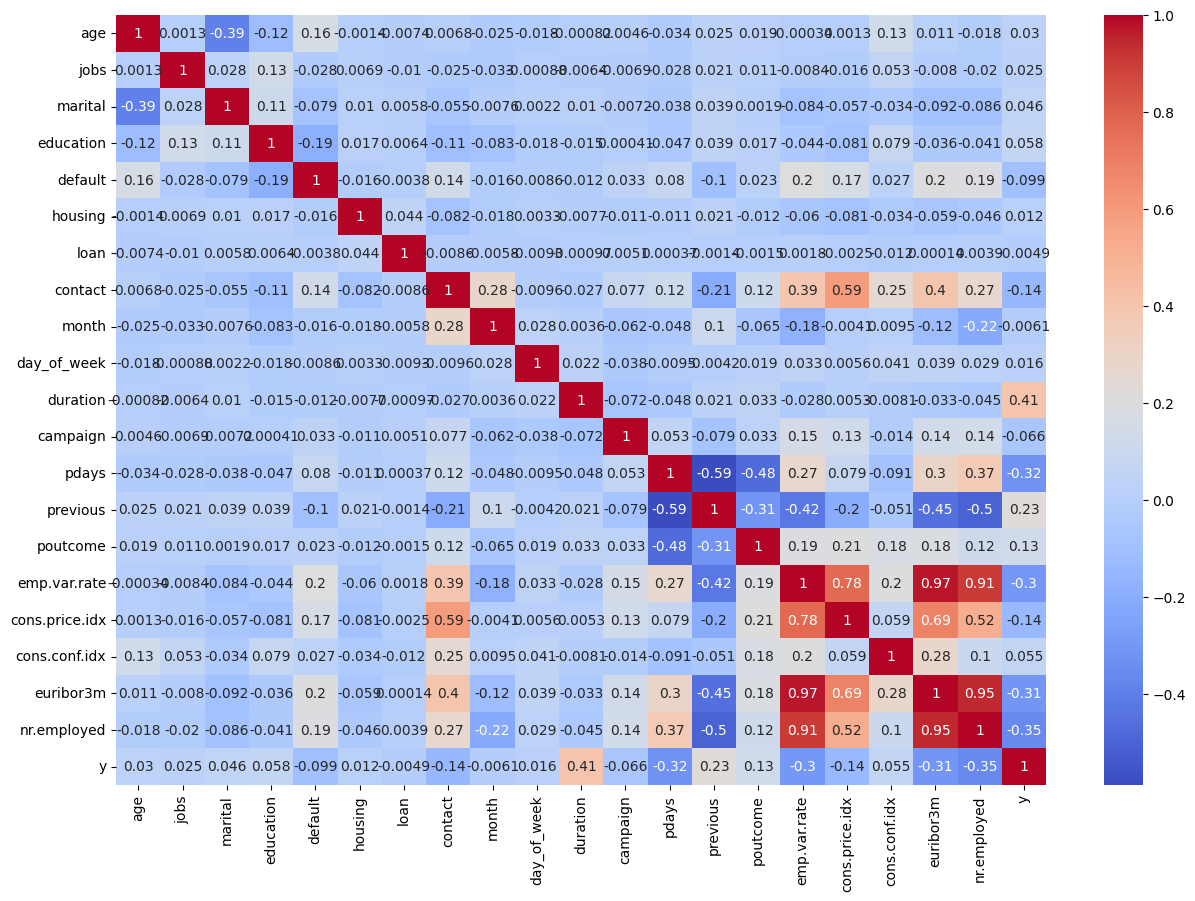

In [ ]:
#heatmap
plt.figure(figsize=(15,10))
sns.heatmap(data= df.corr(),annot = True, cmap = "coolwarm")

In [ ]:
#model building

In [ ]:
#split the data
x = df.iloc[:,:-1]
y=df.iloc[:,-1]

In [ ]:
x

,age,jobs,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
0,56.0,3,1,0,0,0,0,1,6,1,261.0,1.0,999.0,0.0,1,1.1,93.994,-36.4,4.857,5191.0
1,57.0,7,1,3,1,0,0,1,6,1,149.0,1.0,999.0,0.0,1,1.1,93.994,-36.4,4.857,5191.0
2,37.0,7,1,3,0,2,0,1,6,1,226.0,1.0,999.0,0.0,1,1.1,93.994,-36.4,4.857,5191.0
3,40.0,0,1,1,0,0,0,1,6,1,151.0,1.0,999.0,0.0,1,1.1,93.994,-36.4,4.857,5191.0
4,56.0,7,1,3,0,0,2,1,6,1,307.0,1.0,999.0,0.0,1,1.1,93.994,-36.4,4.857,5191.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41184,46.0,1,1,5,0,0,0,0,7,0,383.0,1.0,999.0,0.0,1,-1.1,94.767,-50.8,1.028,4963.6
41185,56.0,5,1,6,0,2,0,0,7,0,189.0,2.0,999.0,0.0,1,-1.1,94.767,-50.8,1.028,4963.6
41186,44.0,9,1,5,0,0,0,0,7,0,442.0,1.0,999.0,0.0,1,-1.1,94.767,-50.8,1.028,4963.6
41187,74.0,5,1,5,0,2,0,0,7,0,239.0,3.0,999.0,1.0,0,-1.1,94.767,-50.8,1.028,4963.6


In [ ]:
y

,y
0,0
1,0
2,0
3,0
4,0
...,...
41184,0
41185,0
41186,1
41187,0


In [ ]:
from sklearn.feature_selection import RFE

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
model = LogisticRegression()

In [ ]:
rfe = RFE(model)

In [ ]:
rfe.fit(x,y)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

RFE(estimator=LogisticRegression())

In [ ]:
column_names = x.columns

In [ ]:
column_names

Index(['age', 'jobs', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed'],
      dtype='object')

In [ ]:
selected_indices = [i for i,data in enumerate(rfe.support_) if data == True]

In [ ]:
selected_indices

[2, 4, 7, 8, 9, 11, 13, 14, 17, 18]

In [ ]:
selected_column_names = [column_names[i] for i in selected_indices]

In [ ]:
selected_column_names

['marital',
 'default',
 'contact',
 'month',
 'day_of_week',
 'campaign',
 'previous',
 'poutcome',
 'cons.conf.idx',
 'euribor3m']

In [ ]:
x = x.loc[:,selected_column_names]

In [ ]:
x

,marital,default,contact,month,day_of_week,campaign,previous,poutcome,cons.conf.idx,euribor3m
0,1,0,1,6,1,1.0,0.0,1,-36.4,4.857
1,1,1,1,6,1,1.0,0.0,1,-36.4,4.857
2,1,0,1,6,1,1.0,0.0,1,-36.4,4.857
3,1,0,1,6,1,1.0,0.0,1,-36.4,4.857
4,1,0,1,6,1,1.0,0.0,1,-36.4,4.857
...,...,...,...,...,...,...,...,...,...,...
41184,1,0,0,7,0,1.0,0.0,1,-50.8,1.028
41185,1,0,0,7,0,2.0,0.0,1,-50.8,1.028
41186,1,0,0,7,0,1.0,0.0,1,-50.8,1.028
41187,1,0,0,7,0,3.0,1.0,0,-50.8,1.028


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
x_train,x_test,y_train,y_test = train_test_split(x,y,train_size = 0.80,random_state = 0)

In [ ]:
lr = LogisticRegression()

In [ ]:
lr.fit(x_train,y_train) # training the data

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [ ]:
y_pred = lr.predict(x_test)

In [ ]:

from sklearn.metrics import *

In [ ]:
accuracy_score(y_test,y_pred)

0.9005585235551239

In [ ]:
report = classification_report(y_pred,y_test)

In [ ]:
print(report)

              precision    recall  f1-score   support

           0       0.99      0.91      0.95      7995
           1       0.19      0.71      0.29       241

    accuracy                           0.90      8236
   macro avg       0.59      0.81      0.62      8236
weighted avg       0.97      0.90      0.93      8236

